# Non-local Haze Radiance Reconstruction


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `nonlocal_haze_radiance_reconstruction` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：observations (1, 400, 600, 3) float64：Native RGB observation divided by 255, dimensionless normalized digital intensity; row, column, RGB order.；airlight (1, 3) float64：Supplied observation-based RGB ambient-light estimate, dimensionless normalized intensity.。恢复目标：restored uint8 RGB display image和float64 transmission。

获取模型：大气haze模型为direct scene乘transmission加airlight散射，RGB共享transmission。实际恢复算法：solvers.haze_line_estimate非局部color-line先验、refine_transmission稀疏逆和recover_radiance。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:11/40无clear scene/depth真值，airlight来自观测；baseline为方法输出。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：nonlocal_haze_radiance_reconstruction.ipynb单元5有保存图；图内容由该单元调用的本地visualization函数生成；nonlocal_haze_radiance_reconstruction.ipynb单元6：5. Results；nonlocal_haze_radiance_reconstruction.ipynb单元7有保存图；图内容由该单元调用的本地visualization函数生成；nonlocal_haze_radiance_reconstruction.ipynb单元8：Refinement ablation and parameter sensitivity；nonlocal_haze_radiance_reconstruction.ipynb单元9有保存图；图内容由该单元调用的本地visualization函数生成；nonlocal_haze_radiance_reconstruction.ipynb单元11有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元5, 7, 9, 11（从0计数）。代码单元5个，带execution_count的5个，保存PNG输出6幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Can a single real hazy photograph recover both a transmission field and an interpretable scene image? Color and depth are confounded: a bright nearby surface can resemble a dark distant one. This review actively reconstructs the full native 400脳600 observation with the cleaned local mathematics. No physical clear-scene truth exists for this sample. Author reproduction and local reproduction are numerical evidence, not independent scene accuracy.

The chosen paper is Berman, Treibitz and Avidan, *Non-Local Image Dehazing*, CVPR2016. Its original code and exact source/data hashes are recorded in `test/validation.md`. This notebook preserves the standard source's haze-line grouping, reliability, WLS refinement and display conventions, and tests their limitations with genuine computed comparisons.

## 2. Data

The real pumpkins image and airlight estimate come from the authors' supplied example. No crop, downsample, synthetic haze or noise is introduced. `observations` is (1,400,600,3) float64 normalized RGB; `airlight` is (1,3) float64, (0.72,0.785,0.81). Gamma is1. Rows increase downward and columns rightward. These camera intensities approximate linear radiometry; exposure, absolute flux and metric distance are unknown.

The original uint8-input demo and normalized floating-input original run are verified separately. The original core converts uint8 to floating point before WLS, so both paths produce identical results. The selected benchmark explicitly bundles those normalized observations and its **unmodified original source** oracle uses the exact same values. The input-equivalence check below is not a different reconstruction method or an upstream error.

In [1]:
from pathlib import Path
import sys,os,time,json,importlib
import numpy as np
import scipy,matplotlib
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.main import run
from src import visualization as vis
from IPython.display import display
import matplotlib.pyplot as plt
%matplotlib inline
image,airlight=load_observations(ROOT/'data/raw_data.npz')
print(json.dumps({'python':sys.executable,'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'shape':image.shape,'dtype':str(image.dtype),'airlight':airlight.tolist()},indent=2))
figures=[];numeric={'observations':image,'airlight':airlight}


{
  "python": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "inline",
  "shape": [
    400,
    600,
    3
  ],
  "dtype": "float64",
  "airlight": [
    0.72,
    0.785,
    0.81
  ]
}


## 3. Physics

At pixel $p$, the observed RGB vector is $I(p)$, clear radiance is $J(p)$, airlight is $A$, and scalar transmission is $t(p)$:

$$I(p)=t(p)J(p)+[1-t(p)]A,\qquad t(p)=e^{-\beta d(p)}.$$

Here $d$ is range and $\beta$ is atmospheric attenuation per unit distance. Only their product is accessible. There are three measured intensities but four unknowns per pixel. A common RGB transmission is an approximation, and the color prior cannot resolve different colors lying on the same airlight-centered line.

Subtracting airlight gives $I-A=t(J-A)$. For a fixed clear color, RGB distance from airlight scales with transmission while direction remains approximately fixed. This is the mathematical basis of non-local haze-lines. It is distinct from merely stretching image contrast.

## 4. Method

Each normalized RGB direction is assigned to its nearest source sphere point among1000fixed directions. Let $r=\|I-A\|_2$, and let $r_{\max}$ be the largest radius in the same haze-line. The initial estimate is $t_0=r/r_{\max}$, floored at0.1, capped at1 and constrained by $t_0\geq1-\min_c I_c/A_c$, where $c$ indexes RGB.

Reliability $w$ combines the number of points and sample standard deviation of their radii. Refinement minimizes

$$\sum_p w(p)[t(p)-t_0(p)]^2+\lambda\sum_{(p,q)\in E}\frac{[t(p)-t(q)]^2}{[G(p)-G(q)]^2+\epsilon},$$

where $E$ is the open four-neighbor grid and $G$ is observed grayscale guidance. The standard source uses $\lambda=0.1$ and $\epsilon=10^{-5}$. After reliability normalization, uncertain top-row pixels are anchored at the column minimum with weight0.8. The local code explicitly assembles the symmetric graph matrix and solves its normal equations; there is no upstream/domain reconstruction import.

The source recovers clipped RGB with residual-haze factor1.06, then contrast-stretches and rounds to uint8. This display is not calibrated physical radiance. These conventions and actual callable defaults are fully explained in the plans. The next cell actively reconstructs, writes a new submission and evaluates it.

Fresh full reconstruction runtime (s): 0.9589743000105955
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0000000000000002,
    "reconstruction_nrmse": 0.0,
    "transmission_ncc": 1.0,
    "transmission_nrmse": 3.6915691293630533e-14
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "transmission_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "transmission_nrmse": {
      "comparison": "<=",
      "boundary": 1e-08
    }
  },
  "errors": []
}


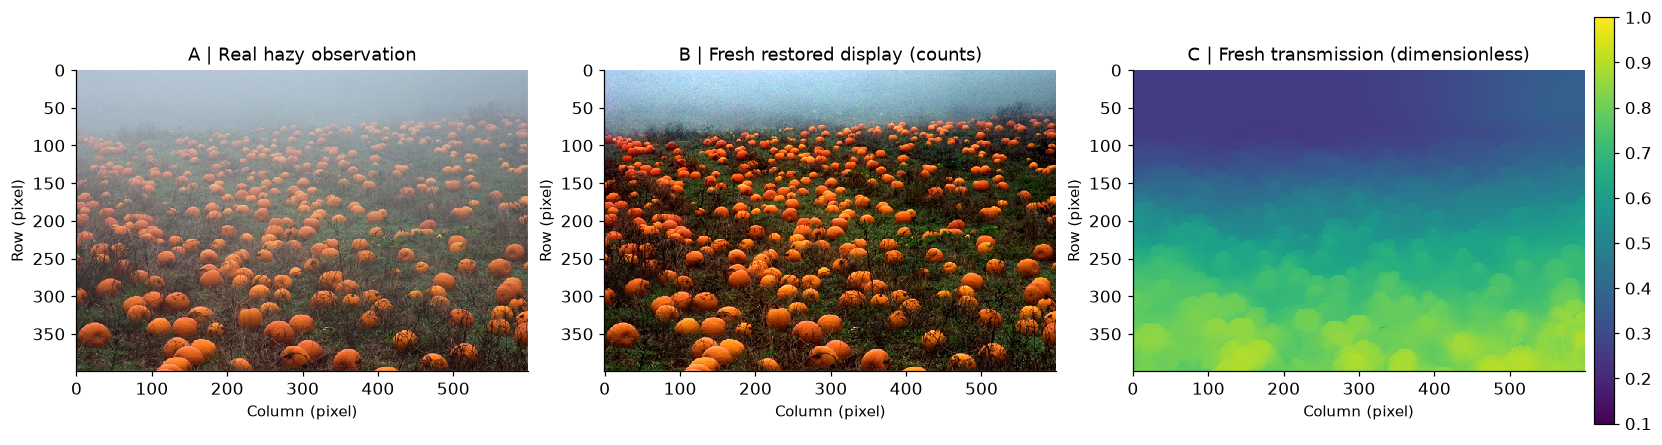

In [2]:
tic=time.perf_counter()
restored,transmission,stages=reconstruct(image,airlight)
runtime=time.perf_counter()-tic
out=ROOT/'output/reconstruction.npz';out.parent.mkdir(exist_ok=True)
np.savez_compressed(out,reconstruction=restored[None],transmission=transmission[None])
import subprocess
result=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(out),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert result.returncode==0,result.stderr
judge_report=json.loads((ROOT/'output/judge_report.json').read_text())
print('Fresh full reconstruction runtime (s):',runtime)
print(json.dumps(judge_report,indent=2))
with np.load(ROOT/'notebooks/reference_outputs/upstream_outputs.npz',allow_pickle=False) as f:
    original_image=f['reconstruction'][0];original_t=f['transmission'][0]
with np.load(ROOT/'notebooks/reference_outputs/original_uint8_input_comparison.npz',allow_pickle=False) as f:legacy_t=f['transmission']
numeric.update(restored_display=restored,transmission=transmission,initial=stages['initial'],weight=stages['weight'],upstream_image=original_image,upstream_transmission=original_t,legacy_uint8_transmission=legacy_t)
figure=vis.observations_and_recovery(image,restored,transmission);figures.append(('01_observation_and_recovery',figure));display(figure);plt.close(figure)


## 5. Results

All maps below are computed on the full bound observations. The five occupied haze-lines shown in RGB space are actual most-populated groups, sampled only for scatter-plot readability; reconstruction uses every pixel. Reliability reveals where the non-local prior has weak support.

The numerical difference plate compares the fresh cleaned result to this task's independently executed original method. The separately reported uint8-versus-normalized-input check verifies preprocessing equivalence, rather than supplying another purported physical truth.

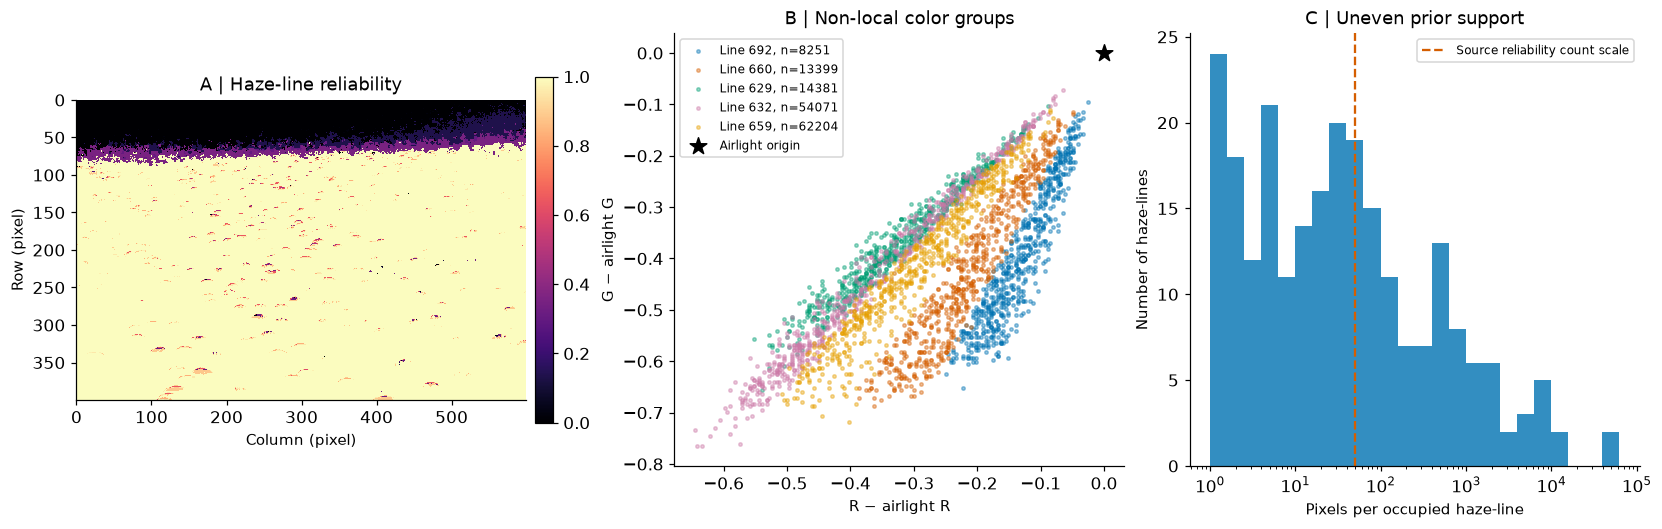

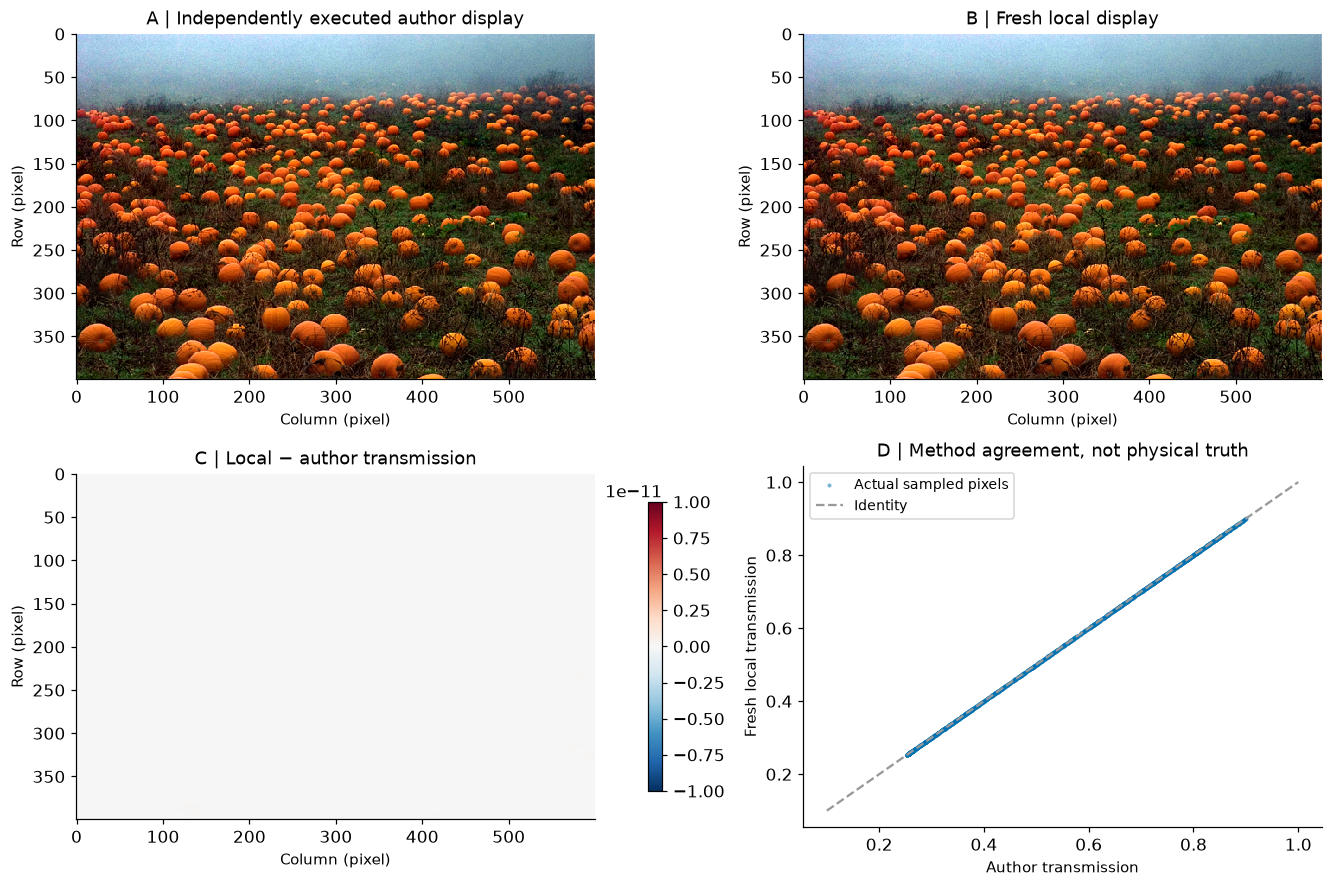

{
  "runtime_seconds": 0.9589743000105955,
  "restored_vs_original": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  },
  "transmission_vs_original": {
    "ncc": 1.0,
    "nrmse": 3.6915691293630533e-14
  },
  "original_input_representation_equivalence": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  },
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_ncc": 1.0000000000000002,
      "reconstruction_nrmse": 0.0,
      "transmission_ncc": 1.0,
      "transmission_nrmse": 3.6915691293630533e-14
    },
    "thresholds": {
      "reconstruction_ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "reconstruction_nrmse": {
        "comparison": "<=",
        "boundary": 0.0001
      },
      "transmission_ncc": {
        "comparison": ">=",
        "boundary": 0.9999999999
      },
      "transmission_nrmse": {
        "comparison": "<=",
        "boundary": 1e-08
      }
    },
    "errors": []
  }
}


In [3]:
figure=vis.haze_line_mechanism(image,airlight,stages);figures.append(('02_haze_line_prior',figure));display(figure);plt.close(figure)
figure=vis.source_comparison(restored,transmission,original_image,original_t);figures.append(('03_original_parity_and_dtype',figure));display(figure);plt.close(figure)
metrics={'runtime_seconds':runtime,'restored_vs_original':vis.compare(restored,original_image),'transmission_vs_original':vis.compare(transmission,original_t),'original_input_representation_equivalence':vis.compare(legacy_t,original_t),'judge':judge_report}
print(json.dumps(metrics,indent=2))


### Refinement ablation and parameter sensitivity

Removing WLS leaves the actual initial haze-line transmission. Its comparison to the selected refined field measures the effect of the spatial prior, not accuracy relative to an unknown depth map. The top-row anchoring is visible and intentionally retained. Three independently recomputed regularization settings show how a stronger prior changes spatial profiles. We report the weighted data and smoothness contributions with the exact matching objective rather than comparing differently normalized losses.

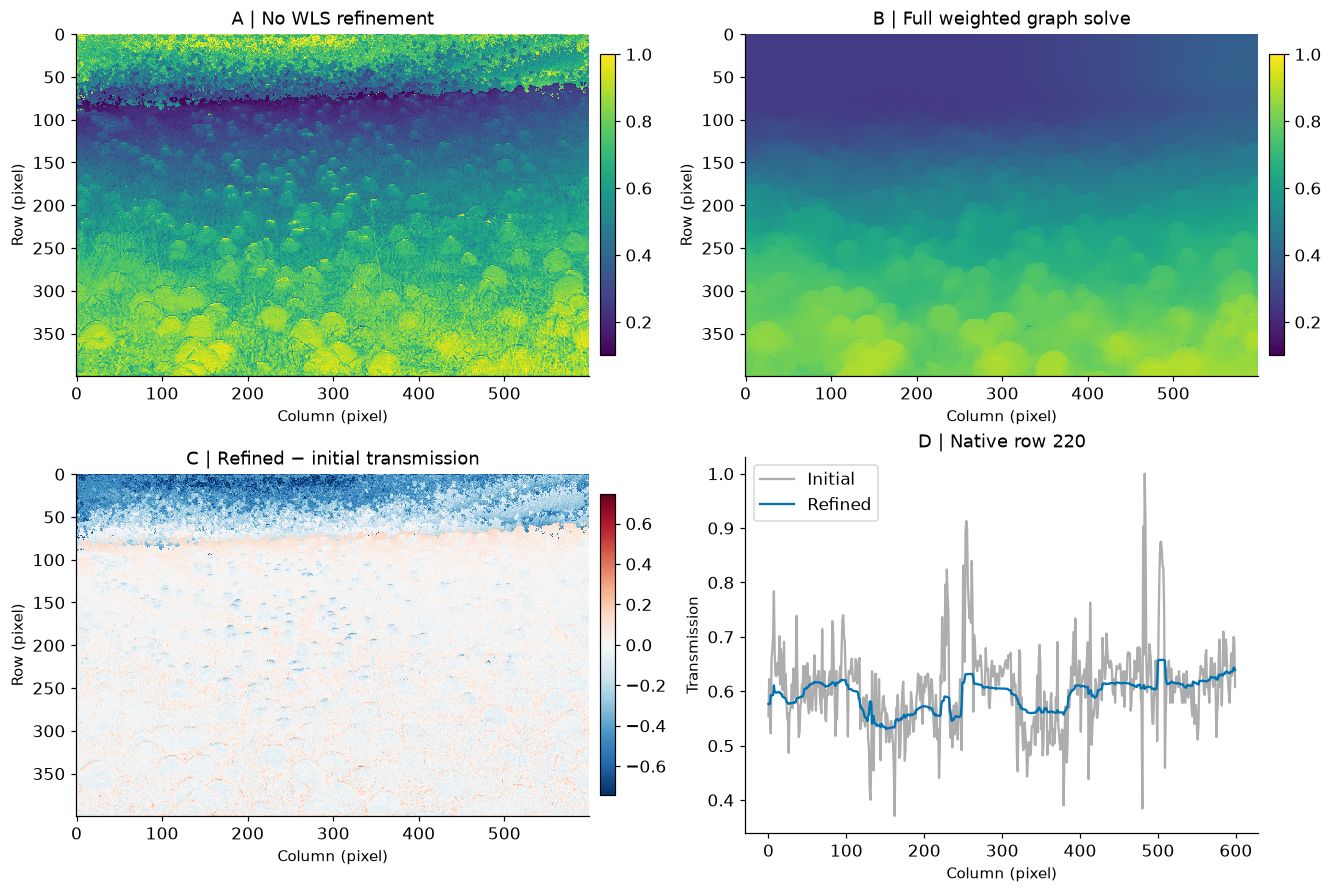

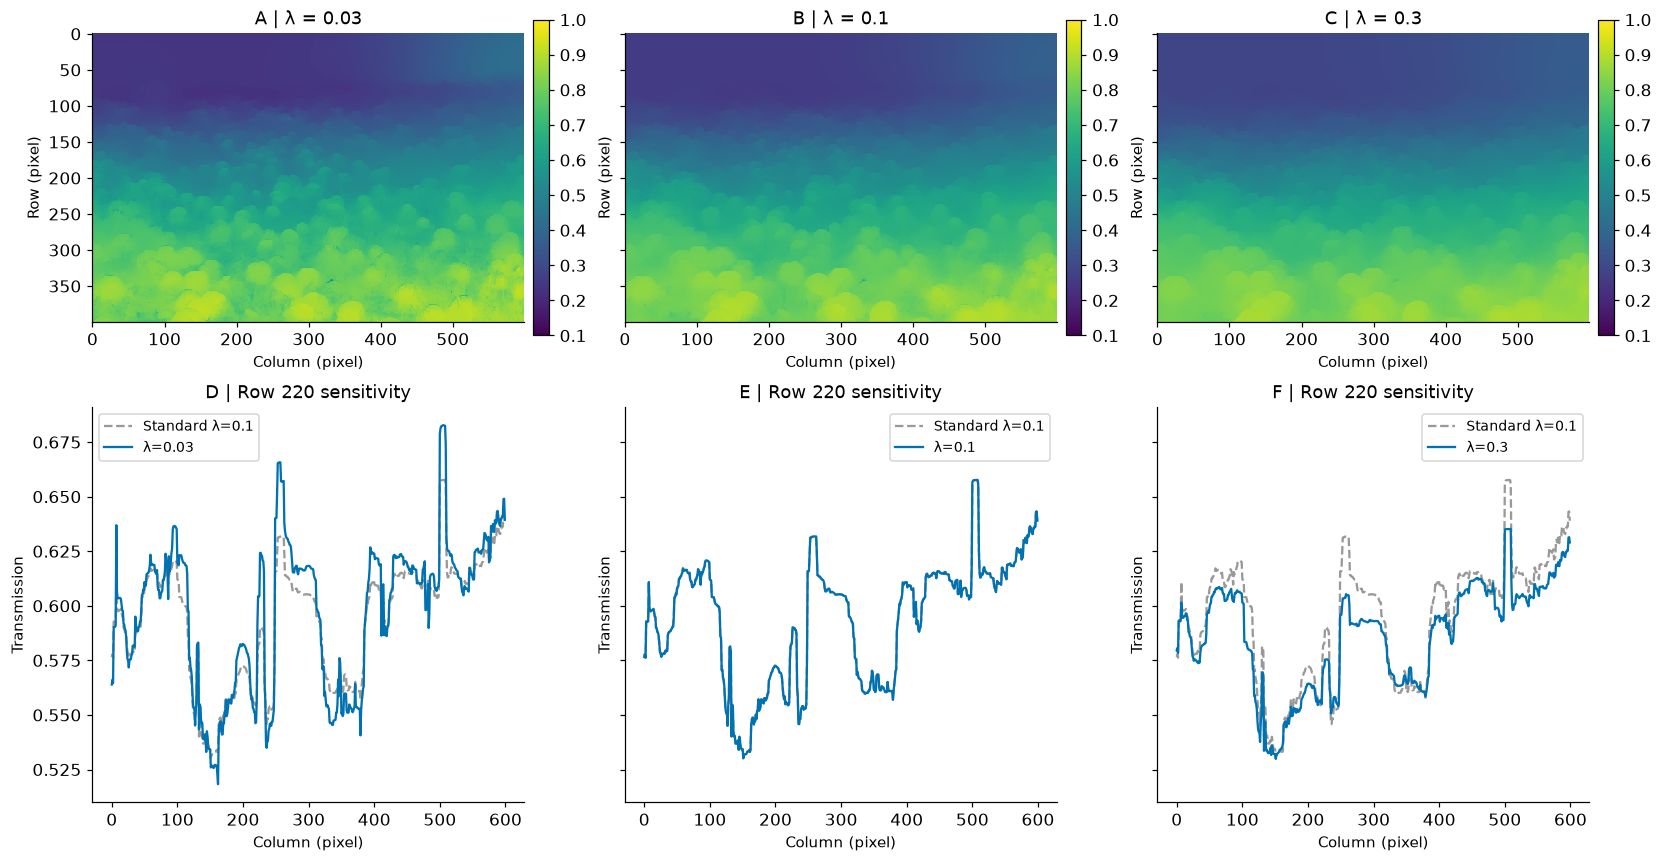

[
  {
    "lambda": 0.03,
    "data_term": 624.9125462132355,
    "smoothness_term": 140.01789369934096,
    "nrmse_vs_standard": 0.020282601847444515
  },
  {
    "lambda": 0.1,
    "data_term": 761.4089975642465,
    "smoothness_term": 199.54187397511788,
    "nrmse_vs_standard": 0.0
  },
  {
    "lambda": 0.3,
    "data_term": 893.5207643259948,
    "smoothness_term": 363.49311967276276,
    "nrmse_vs_standard": 0.023670260154023813
  }
]


In [4]:
figure=vis.refinement_ablation(image,stages);figures.append(('04_refinement_ablation',figure));display(figure);plt.close(figure)
figure,variants,sensitivity_metrics=vis.sensitivity(stages,image)
numeric.update(variants);metrics['lambda_sensitivity']=sensitivity_metrics
figures.append(('05_regularization_sensitivity',figure));display(figure);plt.close(figure)
print(json.dumps(sensitivity_metrics,indent=2))


### Physical consistency versus display appearance

The unbiased atmospheric inverse, the source's deliberate residual-haze convention and the final display have different intensity meanings. We explicitly compute the forward residual of the clipped physical inverse. A small residual demonstrates compatibility with the supplied image equation; it cannot resolve the non-unique pair $(J,t)$. The display's mean brightness is not a quantitative recovery metric.

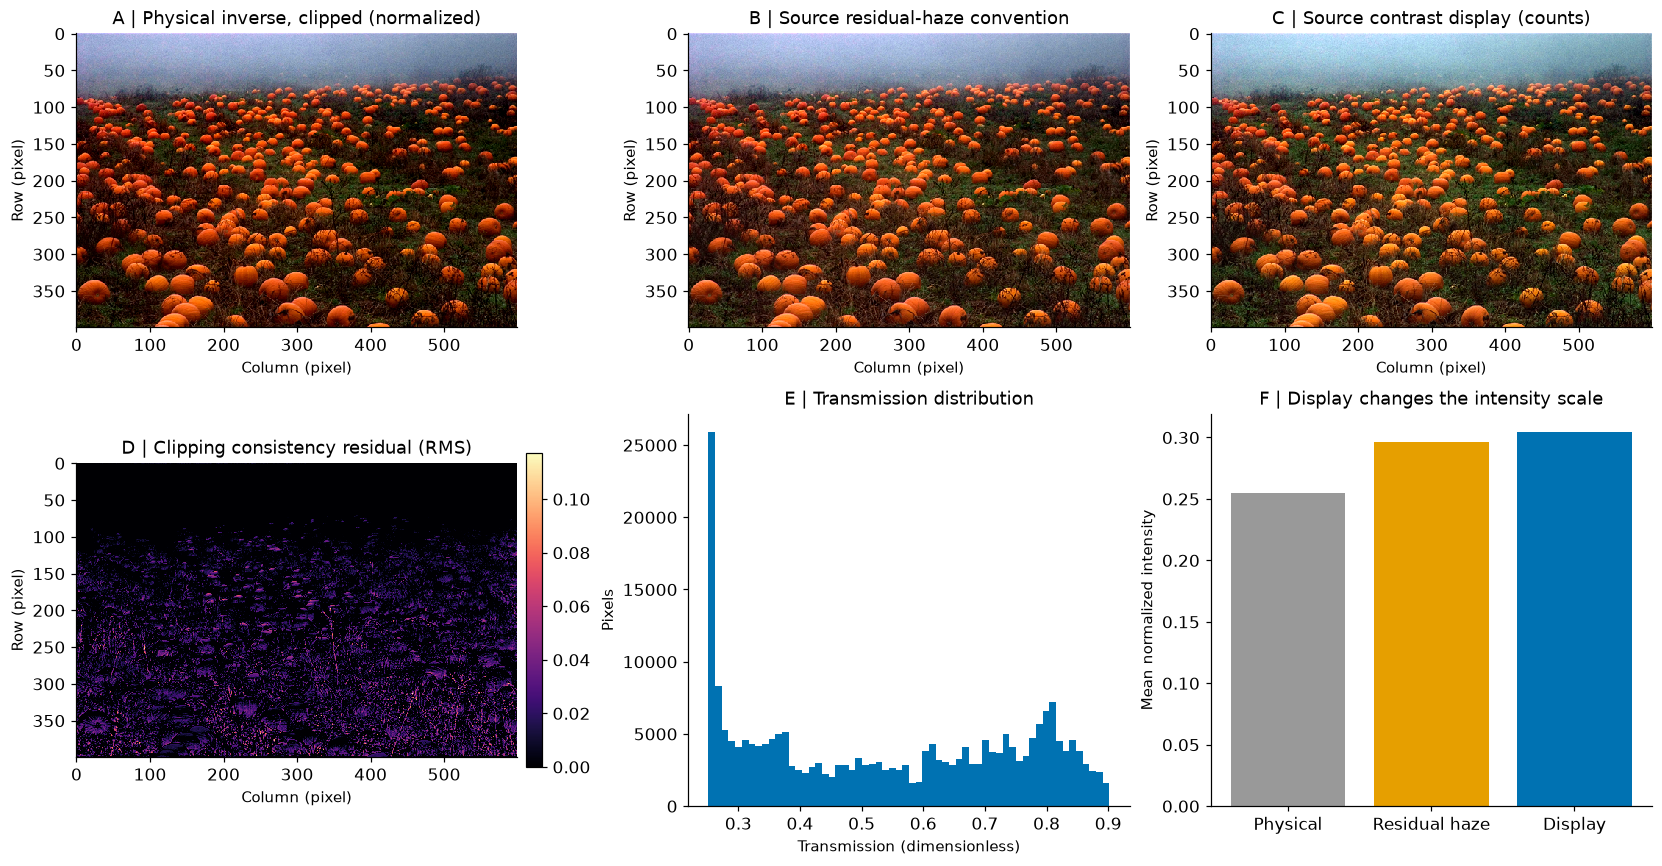

{
  "physical_forward_rms": 0.01310777401220844,
  "figures_computed": 6,
  "private_export_requested": true
}


In [5]:
figure,physical_arrays=vis.physical_and_display_conventions(image,airlight,transmission,restored,stages)
numeric.update(physical_arrays);figures.append(('06_physics_and_display',figure));display(figure);plt.close(figure)
metrics['physical_clipped_forward_rms']=float(np.sqrt(np.mean(physical_arrays['physical_forward_residual']**2)))
archive=os.environ.get('IMAGING101_FIGURE_DIR')
if archive:vis.export_figures(figures,archive,numeric,metrics)
print(json.dumps({'physical_forward_rms':metrics['physical_clipped_forward_rms'],'figures_computed':len(figures),'private_export_requested':bool(archive)},indent=2))


## 6. Conclusion

The full real observation has been actively reconstructed with local mathematical operators. Independent original-stage fixtures, the fresh Judge report and the displayed numerical comparison establish fidelity to the selected normalized-input source method. The ablation and three-setting experiment make the effect of WLS visible, and the input-representation check confirms the original normalization is consistent.

No clear-scene or distance truth was measured for this photograph. Non-local color ambiguity, inaccurate airlight, nonlinear camera response and strong multiple scattering can all invalidate the inferred field. Display clipping, residual-haze bias and contrast stretching further prevent interpreting its enhanced RGB values as absolute radiance. These limits remain part of the report; visual contrast improvement is not substituted for a physical-accuracy claim.